In [5]:
import pandas as pd
import scanpy as sc
import numpy as np
import anndata as ad
import os
import colorcet as cc
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import harmonypy as hm
import scrublet as scr
import traceback
from collections import Counter
from sklearn.decomposition import PCA
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import re
from matplotlib.patches import Patch
from PIL import Image

sc.settings.set_figure_params(dpi=300, dpi_save=300)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

%matplotlib inline

working_dic = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/"
os.chdir(working_dic)

sc.settings.verbosity = 1
sc.logging.print_header()

dimplot_color = mcolors.LinearSegmentedColormap.from_list("custom_cmap", ["#E5E5E5", "#4C4DB7"])
COND_ORDER = [
    "Control",
    "Prematurely-terminated",
    "3month-protocol",
    "6month-protocol",
    "PCMV/PRV",
    "Rejection",
]

COND_COLORS = {
    "Control": "#EFE48E",
    "3month-protocol": "skyblue",
    "6month-protocol": "#08528f",
    "Prematurely-terminated": "#C9B8D9",
    "PCMV/PRV": "#F0C096",
    "Rejection": "#E09E9E",
}


In [6]:
global_annotated_adata_v2 = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/global_object_assembly/objects/global_X_UMAP_Added_PCMV_score_updated_celltype_cellstate_annotated_preclinical_object_RAW_v3.h5ad')


In [7]:
global_annotated_adata_v2

AnnData object with n_obs × n_vars = 233200 × 53826
    obs: 'Sample_ID', 'source', 'doublet_score', 'predicted_doublet_scrublet', 'n_counts_Sus_scrofa', 'n_counts_Papio_anubis', 'species_origin', 'barnyard_doublet', 'Survival', 'Condition', 'Donor_heart_mass (g)', 'Recipient_heart_mass (g)', 'Recipient_LVEF (%)', 'Recipient_LV_Wall_Thickness (mm)', 'TropT (ng/ml)', 'Immunosuppression_Protocol', 'Heart_Mass_Ratio', 'Exp', 'percent_mito', 'percent_ribo', 'n_genes_by_counts', 'total_counts', 'n_counts', 'n_genes', 'n_counts_PCMV', 'n_genes_PCMV', 'PCMV_score', 'cell_type', 'cell_state', 'n_counts_pCMV', 'n_genes_pCMV', 'pCMV_score', 'PCMV_detection_threshold'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'Condition_colors', 'Sample_ID_colors', 'cell_state_colors', 'cell_type_colors'
    obsm: 'X_pca_harmony', 'X_umap', 'X_umap_CM', 'X_umap_EC', 'X_umap_FB', 'X_umap_Lymph_papio', 'X_umap_Lymph_sus', 'X_

# pcmv dotplots

In [19]:

import os
import re
import matplotlib
import matplotlib.pyplot as plt
import scanpy as sc

# --- Adobe Illustrator Vector Graphics Compatibility ---
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42
sc.settings.set_figure_params(dpi=300, dpi_save=300)
matplotlib.rcParams["font.family"] = "sans-serif"
matplotlib.rcParams["font.sans-serif"] = ["Arial"]
plt.rc("font", size=12)

global_annotated_adata_v2 = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/global_object_assembly/objects/global_X_UMAP_Added_PCMV_score_updated_celltype_cellstate_annotated_preclinical_object_RAW_v3.h5ad')

RESULTS_DIR = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/pcmv_genes_dotplot"
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Loading precalculated PCMV preclinical object version 2...")
adata_plot = global_annotated_adata_v2

# Log normalize and scale the data
pcmv_genes = [gene for gene in adata_plot.var_names if re.search("pCMV", gene, re.IGNORECASE)]
print(f"Plotting targets identified: {pcmv_genes}")
sc.pp.normalize_total(adata_plot, target_sum=1e4)
sc.pp.log1p(adata_plot)

# generat etarget visualizations

# --- Plot 1: Dotplot across Cell Types ---
print("Generating individual pCMV gene expression dotplot...")
sc.pl.dotplot(
    adata_plot,
    var_names=pcmv_genes,
    groupby="cell_type",
    cmap="Reds", standard_scale = 'var',
    expression_cutoff=0.0,
    colorbar_title="Mean expression\n(log-normalized)",
    size_title="Fraction of cells\nin group (%)",
    show=False 
)
plt.savefig(os.path.join(RESULTS_DIR, "pcmv_individual_genes_celltype_dotplot.pdf"), bbox_inches="tight", transparent=True)
plt.close()

# Stacked Violins across Cell Types
print("Generating individual pCMV gene expression stacked violin plot...")
sc.pl.stacked_violin(
    adata_plot,
    var_names=pcmv_genes,
    groupby="cell_type",
    cmap="viridis", standard_scale = 'var',
    row_palette="tab20",
    stripplot=False, 
    show=False
)
plt.savefig(os.path.join(RESULTS_DIR, "pcmv_individual_genes_celltype_stacked_violin.pdf"), bbox_inches="tight", transparent=True)
plt.close()

# Make a Matrixplot heatmap across Sample_ID
print("Generating individual pCMV gene expression matrix heatmap...")
sc.pl.matrixplot(
    adata_plot,
    var_names=pcmv_genes,
    groupby="Sample_ID",
    cmap="YlOrRd", standard_scale = 'var',
    colorbar_title="Mean expression",
    show=False
)
plt.savefig(os.path.join(RESULTS_DIR, "pcmv_individual_genes_sample_matrixplot.pdf"), bbox_inches="tight", transparent=True)
plt.close()

print(f"\nAll viral gene visualization scripts completed. Plots exported to:\n{RESULTS_DIR}")

Loading precalculated PCMV preclinical object version 2...
Plotting targets identified: ['pCMV_____gp01', 'pCMV_____gp02', 'pCMV_____gp03', 'pCMV_____gp04', 'pCMV_____gp05', 'pCMV_____gp06', 'pCMV_____gp07', 'pCMV_____gp08', 'pCMV_____gp09', 'pCMV_____gp10', 'pCMV_____gp11', 'pCMV_____gp12', 'pCMV_____gp13', 'pCMV_____gp14', 'pCMV_____gp15', 'pCMV_____gp16', 'pCMV_____gp17', 'pCMV_____gp18', 'pCMV_____gp19', 'pCMV_____gp20', 'pCMV_____gp21', 'pCMV_____gp22', 'pCMV_____gp23', 'pCMV_____gp24', 'pCMV_____gp25', 'pCMV_____gp26', 'pCMV_____gp27', 'pCMV_____gp28', 'pCMV_____gp29', 'pCMV_____gp30', 'pCMV_____gp31', 'pCMV_____gp32', 'pCMV_____gp33', 'pCMV_____gp34', 'pCMV_____gp35', 'pCMV_____gp36', 'pCMV_____gp37', 'pCMV_____gp38', 'pCMV_____gp39', 'pCMV_____gp40', 'pCMV_____gp41', 'pCMV_____gp42', 'pCMV_____gp43', 'pCMV_____gp44', 'pCMV_____gp45', 'pCMV_____gp46', 'pCMV_____gp47', 'pCMV_____gp48', 'pCMV_____gp49', 'pCMV_____gp50', 'pCMV_____gp51', 'pCMV_____gp52', 'pCMV_____gp53', 'pCMV_____

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

Generating individual pCMV gene expression stacked violin plot...


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

Generating individual pCMV gene expression matrix heatmap...


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because


All viral gene visualization scripts completed. Plots exported to:
/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/pcmv_genes_dotplot


# pcmv gene expression boxplots

In [9]:
import os
import re
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

sc.settings.set_figure_params(dpi=300, dpi_save=300)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
matplotlib.rcParams["font.family"] = "sans-serif"
matplotlib.rcParams["font.sans-serif"] = ["Arial"]

# Load the adata file
print("Loading preclinical AnnData object v2...")
adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/global_object_assembly/objects/global_X_UMAP_Added_PCMV_score_updated_celltype_cellstate_annotated_preclinical_object_RAW_v3.h5ad')


RESULTS_DIR = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/mean_pcmv_expression_boxplots"
os.makedirs(RESULTS_DIR, exist_ok=True)

# User Dictionary representing marker_genes_list
marker_genes_dict = {
    "pCMV": [
        'pCMV_____gp01', 'pCMV_____gp02', 'pCMV_____gp03', 'pCMV_____gp04', 'pCMV_____gp05', 'pCMV_____gp06', 'pCMV_____gp07', 
        'pCMV_____gp08', 'pCMV_____gp09', 'pCMV_____gp10', 'pCMV_____gp11', 'pCMV_____gp12', 'pCMV_____gp13', 'pCMV_____gp14', 
        'pCMV_____gp15', 'pCMV_____gp16', 'pCMV_____gp17', 'pCMV_____gp18', 'pCMV_____gp19', 'pCMV_____gp20', 'pCMV_____gp21', 
        'pCMV_____gp22', 'pCMV_____gp23', 'pCMV_____gp24', 'pCMV_____gp25', 'pCMV_____gp26', 'pCMV_____gp27', 'pCMV_____gp28', 
        'pCMV_____gp29', 'pCMV_____gp30', 'pCMV_____gp31', 'pCMV_____gp32', 'pCMV_____gp33', 'pCMV_____gp34', 'pCMV_____gp35', 
        'pCMV_____gp36', 'pCMV_____gp37', 'pCMV_____gp38', 'pCMV_____gp39', 'pCMV_____gp40', 'pCMV_____gp41', 'pCMV_____gp42', 
        'pCMV_____gp43', 'pCMV_____gp44', 'pCMV_____gp45', 'pCMV_____gp46', 'pCMV_____gp47', 'pCMV_____gp48', 'pCMV_____gp49', 
        'pCMV_____gp50', 'pCMV_____gp51', 'pCMV_____gp52', 'pCMV_____gp53', 'pCMV_____gp54', 'pCMV_____gp55', 'pCMV_____gp56', 
        'pCMV_____gp57', 'pCMV_____gp58', 'pCMV_____gp59', 'pCMV_____gp60', 'pCMV_____gp61', 'pCMV_____gp62', 'pCMV_____gp63', 
        'pCMV_____gp64', 'pCMV_____gp65', 'pCMV_____gp66', 'pCMV_____gp67', 'pCMV_____gp68', 'pCMV_____gp69', 'pCMV_____gp70', 
        'pCMV_____gp71', 'pCMV_____gp72', 'pCMV_____gp73', 'pCMV_____gp74', 'pCMV_____gp75', 'pCMV_____gp76', 'pCMV_____gp77',  'pCMV_____gp78', 'pCMV_____gp79', 'pCMV_____gp80'
    ]
}


condition_order = ["Control", "Prematurely-terminated", "3month-protocol", "6month-protocol", "PCMV/PRV", "Rejection"]

# Extract unique mapping of Sample_ID to Condition
unique_mapping = adata.obs[['Sample_ID', 'Condition']].drop_duplicates()

# Force the condition column into a Categorical type with our explicit sorted order
unique_mapping['Condition'] = pd.Categorical(unique_mapping['Condition'], categories=condition_order, ordered=True)

# Sort the dataframe first by Condition (respecting the order above), then alphabetically by Sample_ID
unique_mapping = unique_mapping.sort_values(['Condition', 'Sample_ID'])

# Extract the sorted samples to serve as our dynamic array
sample_order = unique_mapping['Sample_ID'].tolist()
print(f"Dynamically calculated Sample Order: {sample_order}")


# 1. data extraction and pseudobulking

print("\nCalculating temporary normalization states...")
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

all_raw_query_genes = list(set([g for group in marker_genes_dict.values() for g in group]))

var_names_map = {g.replace("-", "_"): g for g in adata.var_names}
valid_adata_genes = []
translation_dict = {}

for g in all_raw_query_genes:
    standardized_name = g.replace("-", "_")
    if standardized_name in var_names_map:
        actual_obj_name = var_names_map[standardized_name]
        valid_adata_genes.append(actual_obj_name)
        translation_dict[actual_obj_name] = g 

print(f"Validated {len(valid_adata_genes)} of {len(all_raw_query_genes)} target features inside object index.")

expression_matrix = adata[:, valid_adata_genes].X
if not isinstance(expression_matrix, np.ndarray):
    expression_matrix = expression_matrix.toarray()

expr_df = pd.DataFrame(expression_matrix, columns=valid_adata_genes, index=adata.obs_names)
expr_df["Sample_ID"] = adata.obs["Sample_ID"].values
expr_df["Condition"] = adata.obs["Condition"].values

# generate and save detailed CSVs
print("\nComputing and saving detailed pseudobulk expression CSV tables...")

# CSV 1: Mean expression profile per Sample_ID
sample_means_t = expr_df.groupby("Sample_ID", observed=False).mean(numeric_only=True).T.rename(index=translation_dict)
available_samples = [s for s in sample_order if s in sample_means_t.columns]
sample_means_csv = sample_means_t[available_samples]
sample_csv_path = os.path.join(RESULTS_DIR, "pcmv_mean_expression_per_sample.csv")
sample_means_csv.to_csv(sample_csv_path, index_label="Gene")
print(f" -> Saved Sample CSV: {sample_csv_path}")

# CSV 2: Mean expression profile per condition
condition_means_t = expr_df.groupby("Condition", observed=False).mean(numeric_only=True).T.rename(index=translation_dict)
available_conditions = [c for c in condition_order if c in condition_means_t.columns]
condition_means_csv = condition_means_t[available_conditions]
condition_csv_path = os.path.join(RESULTS_DIR, "pcmv_mean_expression_per_condition.csv")
condition_means_csv.to_csv(condition_csv_path, index_label="Gene")
print(f" -> Saved Condition CSV: {condition_csv_path}")


# 2. Plottings
for group_name, gene_list in marker_genes_dict.items():
    print(f"\nProcessing plotting matrices for group [{group_name}]...")
    

    # part 1: Sample_ID distribution plot

    genes_in_samples = [g for g in gene_list if g in sample_means_csv.index]
    if len(genes_in_samples) > 0:
        plot_sample_df = sample_means_csv.loc[genes_in_samples].reset_index().rename(columns={"index": "Gene"})
        plot_sample_df = pd.melt(plot_sample_df, id_vars=["Gene"], var_name="Sample", value_name="Mean_Expression")
        
        plot_sample_df["Sample"] = pd.Categorical(plot_sample_df["Sample"], categories=available_samples, ordered=True)
        plot_sample_df["Mean_Expression"] = plot_sample_df["Mean_Expression"].astype(float)
        
        plt.figure(figsize=(12, 9))  # Slightly wider to accommodate dynamic sample names
        sns.set_style("ticks")
        
        ax_sample = sns.boxplot(
            data=plot_sample_df, x="Sample", y="Mean_Expression", order=available_samples,
            color="#A85D75", width=0.5,
            boxprops=dict(linewidth=1.2, edgecolor="black"),
            whiskerprops=dict(linewidth=1.2, color="black"),
            capprops=dict(linewidth=1.2, color="black"),
            medianprops=dict(linewidth=1.2, color="black"), fliersize=0
        )
        sns.stripplot(
            data=plot_sample_df, x="Sample", y="Mean_Expression", order=available_samples,
            color="black", size=5, alpha=0.8, jitter=0.2, dodge=False, zorder=3
        )
        
        plt.title(f"Distribution of Mean Gene Expression for {group_name} Genes (by Sample)", fontsize=16, pad=15, fontweight="bold")
        plt.xlabel("Patient / Sample", fontsize=12, fontweight="bold")
        plt.ylabel("Mean expression of pCMV/PRV genes", fontsize=12, fontweight="bold")
        plt.xticks(rotation=45, ha="right", fontweight="bold")
        plt.yticks(fontweight="bold")
        
        ax_sample.spines["top"].set_visible(False)
        ax_sample.spines["right"].set_visible(False)
        ax_sample.spines["left"].set_visible(True)
        ax_sample.spines["bottom"].set_visible(True)
        ax_sample.spines["left"].set_linewidth(1.5)
        ax_sample.spines["bottom"].set_linewidth(1.5)
        
        plt.tight_layout()
        out_sample_pdf = os.path.join(RESULTS_DIR, f"pcmv_expression_boxplot_{group_name}_per_Sample_ID.pdf")
        plt.savefig(out_sample_pdf, dpi=300, bbox_inches="tight", transparent=True)
        plt.close()
        print(f" -> Saved Sample ID Boxplot: {out_sample_pdf}")


    # part 2: Condition distribution lot

    genes_in_conditions = [g for g in gene_list if g in condition_means_csv.index]
    if len(genes_in_conditions) > 0:
        plot_cond_df = condition_means_csv.loc[genes_in_conditions].reset_index().rename(columns={"index": "Gene"})
        plot_cond_df = pd.melt(plot_cond_df, id_vars=["Gene"], var_name="Condition", value_name="Mean_Expression")
        
        plot_cond_df["Condition"] = pd.Categorical(plot_cond_df["Condition"], categories=available_conditions, ordered=True)
        plot_cond_df["Mean_Expression"] = plot_cond_df["Mean_Expression"].astype(float)
        
        plt.figure(figsize=(12, 9))
        sns.set_style("ticks")
        
        ax_cond = sns.boxplot(
            data=plot_cond_df, x="Condition", y="Mean_Expression", order=available_conditions,
            color= "#A85D75", width=0.5,
            boxprops=dict(linewidth=1.2, edgecolor="black"),
            whiskerprops=dict(linewidth=1.2, color="black"),
            capprops=dict(linewidth=1.2, color="black"),
            medianprops=dict(linewidth=1.2, color="black"), fliersize=0
        )
        sns.stripplot(
            data=plot_cond_df, x="Condition", y="Mean_Expression", order=available_conditions,
            color="black", size=5, alpha=0.8, jitter=0.2, dodge=False, zorder=3
        )
        
        plt.title(f"Distribution of Mean Gene Expression for {group_name} Genes (by Condition)", fontsize=16, pad=15, fontweight="bold")
        plt.xlabel("Condition", fontsize=12, fontweight="bold")
        plt.ylabel("Mean expression of pCMV/PRV genes", fontsize=12, fontweight="bold")
        plt.xticks(rotation=45, ha="right", fontweight="bold")
        plt.yticks(fontweight="bold")
        
        ax_cond.spines["top"].set_visible(False)
        ax_cond.spines["right"].set_visible(False)
        ax_cond.spines["left"].set_visible(True)
        ax_cond.spines["bottom"].set_visible(True)
        ax_cond.spines["left"].set_linewidth(1.5)
        ax_cond.spines["bottom"].set_linewidth(1.5)
        
        plt.tight_layout()
        out_cond_pdf = os.path.join(RESULTS_DIR, f"pcmv_expression_boxplot_{group_name}_per_Condition.pdf")
        plt.savefig(out_cond_pdf, dpi=300, bbox_inches="tight", transparent=True)
        plt.close()
        print(f" -> Saved Condition Boxplot: {out_cond_pdf}")

print("\nDone! All pipeline aggregations and automated ordered distributions successfully generated.")

Loading preclinical AnnData object v2...
Dynamically calculated Sample Order: ['5411-2', '5806-2', '7159', '7518', 'PAV83', 'PAV84', 'PAV88', 'PAV65', 'PAV66', 'PAV67', 'PAV69', 'PAV75', 'PAV80', 'PAV82', 'PAV71', 'PAV72', 'PAV85', 'PAV87-1', 'PAV68', 'PAV73', 'PAV74', 'PAV76', 'PAV78', 'PAV79', 'PAV86', 'PAV89']

Calculating temporary normalization states...
Validated 80 of 80 target features inside object index.

Computing and saving detailed pseudobulk expression CSV tables...
 -> Saved Sample CSV: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/mean_pcmv_expression_boxplots/pcmv_mean_expression_per_sample.csv
 -> Saved Condition CSV: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/mean_pcmv_expression_boxplots/pcmv_mean_expression_per_condition.csv

Processing plotting matrices for group [pCMV]...
 -> Saved Sample ID Boxplot: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/

# PCMV detection per cell type per Sample_ID

In [5]:

import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

sc.settings.set_figure_params(dpi=300, dpi_save=300)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
matplotlib.rcParams["font.family"] = "sans-serif"
matplotlib.rcParams["font.sans-serif"] = ["Arial"]

RESULTS_DIR = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/pcmv_per_celltype_per_sample'
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Loading preclinical AnnData object v2...")
adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/global_object_assembly/objects/global_X_UMAP_Added_PCMV_score_updated_celltype_cellstate_annotated_preclinical_object_RAW_v3.h5ad')

condition_order = ["Control", "Prematurely-terminated", "3month-protocol", "6month-protocol", "PCMV/PRV", "Rejection"]

# Extract unique mapping of Sample_ID to Condition directly from observations metadata
unique_mapping = adata.obs[['Sample_ID', 'Condition']].drop_duplicates()
unique_mapping['Condition'] = pd.Categorical(unique_mapping['Condition'], categories=condition_order, ordered=True)

# Sort by structural cohort criteria condition tier first, then by alphanumeric sample tracking labels
unique_mapping = unique_mapping.sort_values(['Condition', 'Sample_ID'])
sample_order = unique_mapping['Sample_ID'].tolist()
print(f"Dynamically calculated Sample Order matching cohort tracking: {sample_order}")

df = adata.obs[['Sample_ID', 'cell_type', 'n_counts_pCMV']].copy()
df['n_counts_pCMV'] = df['n_counts_pCMV'].fillna(0)

# Aggregate total viral load per sample and major cellular lineage
sample_stats = (
    df.groupby(['Sample_ID', 'cell_type'], observed=False)['n_counts_pCMV']
    .sum()
    .reset_index()
    .rename(columns={'n_counts_pCMV': 'total_viral'})
)

csv_out_path = os.path.join(RESULTS_DIR, 'pCMV_viral_load_by_sample_grouped.csv')
sample_stats.to_csv(csv_out_path, index=False)
print(f"Associated CSV saved -> {csv_out_path}")

# Filter sample order array down to samples present in current stats matrix slice
sample_order = [s for s in sample_order if s in sample_stats['Sample_ID'].unique()]

# Order cell types by total viral load magnitude
celltype_order = (
    sample_stats.groupby('cell_type', observed=False)['total_viral']
    .sum()
    .sort_values(ascending=False)
    .index.tolist()
)

n_celltypes = len(celltype_order)
bar_width = 0.8 / n_celltypes
palette = sns.color_palette('tab20', n_colors=n_celltypes)

# Plot

plt.figure(figsize=(12, 6))
plt.rcParams.update({'font.size': 14})

# Plot each cell type's bar layer grouped per sample bucket
for i, cell_type in enumerate(celltype_order):
    cell_data = sample_stats[sample_stats['cell_type'] == cell_type]
    y_vals = cell_data.set_index('Sample_ID').reindex(sample_order)['total_viral'].fillna(0).values
    x_vals = np.arange(len(sample_order)) + i * bar_width
    plt.bar(x_vals, y_vals, width=bar_width, label=cell_type, color=palette[i], edgecolor='black', linewidth=0.5)

plt.title('Total pCMV viral transcripts per Sample (grouped by cell type)', fontsize=16, pad=20, fontweight='bold')
plt.xlabel('Sample ID', fontsize=14, fontweight='bold')
plt.ylabel('Total pCMV Transcripts', fontsize=14, fontweight='bold')

plt.xticks(
    np.arange(len(sample_order)) + (bar_width * n_celltypes / 2) - bar_width / 2,
    sample_order,
    rotation=45,
    ha='right',
    fontweight='bold'
)

plt.legend(title='Cell Type', bbox_to_anchor=(1.02, 1), loc='upper left', edgecolor='black')
plt.grid(axis='y', alpha=0.3)
sns.despine()
plt.tight_layout()

pdf_out_path = os.path.join(RESULTS_DIR, 'pCMV_viral_load_by_sample_grouped.pdf')
plt.savefig(pdf_out_path, dpi=300, bbox_inches="tight", transparent=True)
plt.close()
print(f"Plot figure saved -> {pdf_out_path}")


# PCMV_detection per cell type across the whole dataset

In [4]:
import os
import re
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.cm as cm

sc.settings.set_figure_params(dpi=300, dpi_save=300)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
matplotlib.rcParams["font.family"] = "sans-serif"
matplotlib.rcParams["font.sans-serif"] = ["Arial"]

# define paths 
RESULTS_DIR = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/pcmv_detection_pct_per_celltype_in_whole_dataset/'
os.makedirs(RESULTS_DIR, exist_ok=True)

adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/global_object_assembly/objects/global_X_UMAP_Added_PCMV_score_updated_celltype_cellstate_annotated_preclinical_object_RAW_v3.h5ad')

# Quantify detection fractions
adata.obs['PCMV_detection_threshold_num'] = adata.obs['PCMV_detection_threshold'].astype(int)

# Use observed=False to protect categorical groupings from dropping unobserved categories
detection_percentages = adata.obs.groupby('cell_type', observed=False)['PCMV_detection_threshold_num'].mean() * 100
detection_df = (
    detection_percentages
    .reset_index()
    .rename(columns={'PCMV_detection_threshold_num': 'pct_detected'})
)

# Sort by load magnitude across all existing cell types
detection_df = detection_df.sort_values('pct_detected', ascending=False)
cell_type_order = detection_df['cell_type'].tolist()

# Save dataframe table to CSV
csv_out_path = os.path.join(RESULTS_DIR, 'pCMV_pct_detected_by_cell_type.csv')
detection_df.to_csv(csv_out_path, index=False)
print(f"Associated CSV saved -> {csv_out_path}")

# plot

plt.figure(figsize=(6, 4))
x = np.arange(len(cell_type_order))
y = detection_df.set_index('cell_type').loc[cell_type_order, 'pct_detected'].values

bars = plt.bar(x, y, width=0.7)
plt.title('Percentage of cells with PCMV/PRV detection per cell type in whole dataset', fontsize=14, fontweight='bold', pad=14)
plt.xlabel('Cell Type', fontsize=12, fontweight='bold')
plt.ylabel('Percentage detected', fontsize=12, fontweight='bold')
plt.xticks(x, cell_type_order, rotation=45, ha='right', fontsize=11, fontweight='bold')
plt.yticks(fontsize=11)

# dynamic y headroom
ymax = (np.nanmax(y) if len(y) else 0) * 1.25
plt.ylim(0, max(1.0, ymax))

# viridis gradient masking
colors = cm.get_cmap("viridis")(np.linspace(0.2, 0.9, len(bars)))
for rect, color in zip(bars, colors):
    rect.set_color(color)
    rect.set_edgecolor("black")
    rect.set_linewidth(1.0)

# Text placement loop
ax = plt.gca()
axis_range = ax.get_ylim()[1] - ax.get_ylim()[0]
offset = 0.015 * axis_range

for rect in bars:
    height = rect.get_height()
    label = f"{height:.2f}%"
    plt.annotate(
        label,
        (rect.get_x() + rect.get_width()/2., height),
        ha="center", va="bottom",
        xytext=(0, max(offset, 0.02)), textcoords="offset points",
        fontsize=10, fontweight="bold", color="black",
        clip_on=False
    )
ax.grid(False)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)

plt.tight_layout()
pdf_out_path = os.path.join(RESULTS_DIR, 'pCMV_pct_detected_by_cell_type.pdf')
plt.savefig(pdf_out_path, dpi=300, bbox_inches='tight', transparent=True)
plt.close()
print(f"Plot figure saved -> {pdf_out_path}")

# PCMV_detection per cell type in the Condition = PCMV/PRV

In [3]:
import os
import re
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.cm as cm
sc.settings.set_figure_params(dpi=300, dpi_save=300)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
matplotlib.rcParams["font.family"] = "sans-serif"
matplotlib.rcParams["font.sans-serif"] = ["Arial"]

# --- Paths ---
RESULTS_DIR = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/pcmv_detection_pct_per_celltype_in_pcmv_condition/'
os.makedirs(RESULTS_DIR, exist_ok=True)

adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/global_object_assembly/objects/global_X_UMAP_Added_PCMV_score_updated_celltype_cellstate_annotated_preclinical_object_RAW_v3.h5ad')

# Cohort subsettings

print("Subsetting object context exclusively for Condition == 'PCMV/PRV'...")
adata = adata[adata.obs['Condition'] == 'PCMV/PRV'].copy()
print(f"Cohort snapshot matrix dimensions: {adata.n_obs} cells remaining.")

if adata.n_obs == 0:
    raise ValueError("Failure: No cells found matching Condition == 'PCMV/PRV'. Check metadata naming keys.")

# Quantify detection fractions
adata.obs['PCMV_detection_threshold_num'] = adata.obs['PCMV_detection_threshold'].astype(int)

# Use observed=False to protect categorical groupings from dropping unobserved categories
detection_percentages = adata.obs.groupby('cell_type', observed=False)['PCMV_detection_threshold_num'].mean() * 100
detection_df = (
    detection_percentages
    .reset_index()
    .rename(columns={'PCMV_detection_threshold_num': 'pct_detected'})
)

# Sort by load magnitude automatically for all cell types inside this condition
detection_df = detection_df.sort_values('pct_detected', ascending=False)
cell_type_order = detection_df['cell_type'].tolist()

# Save dataframe table to CSV (Appended with cohort suffix)
csv_out_path = os.path.join(RESULTS_DIR, 'pCMV_pct_detected_by_cell_type_PCMV_PRV_cohort.csv')
detection_df.to_csv(csv_out_path, index=False)
print(f"Associated CSV saved -> {csv_out_path}")

# plot

plt.figure(figsize=(6, 4))
x = np.arange(len(cell_type_order))
y = detection_df.set_index('cell_type').loc[cell_type_order, 'pct_detected'].values

bars = plt.bar(x, y, width=0.7)
plt.title('Percentage of cells with PCMV/PRV detection per cell type in the PCMV/PRV condition', fontsize=12, fontweight='bold', pad=14)
plt.xlabel('Cell Type', fontsize=11, fontweight='bold')
plt.ylabel('Percentage detected', fontsize=11, fontweight='bold')
plt.xticks(x, cell_type_order, rotation=45, ha='right', fontsize=10, fontweight='bold')
plt.yticks(fontsize=10)

# Dynamic y headroom
ymax = (np.nanmax(y) if len(y) else 0) * 1.25
plt.ylim(0, max(1.0, ymax))

# Viridis gradient masking
colors = cm.get_cmap("viridis")(np.linspace(0.2, 0.9, len(bars)))
for rect, color in zip(bars, colors):
    rect.set_color(color)
    rect.set_edgecolor("black")
    rect.set_linewidth(1.0)

# Text placement loop

ax = plt.gca()
axis_range = ax.get_ylim()[1] - ax.get_ylim()[0]
offset = 0.015 * axis_range

for rect in bars:
    height = rect.get_height()
    label = f"{height:.2f}%"
    plt.annotate(
        label,
        (rect.get_x() + rect.get_width()/2., height),
        ha="center", va="bottom",
        xytext=(0, max(offset, 0.02)), textcoords="offset points",
        fontsize=9, fontweight="bold", color="black",
        clip_on=False
    )
ax.grid(False)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)

plt.tight_layout()
pdf_out_path = os.path.join(RESULTS_DIR, 'pCMV_pct_detected_by_cell_type_PCMV_PRV_cohort.pdf')
plt.savefig(pdf_out_path, dpi=300, bbox_inches='tight', transparent=True)
plt.close()
print(f"Plot figure saved -> {pdf_out_path}")


# Feature plots of pcmv genes

In [1]:

dimplot_color = mcolors.LinearSegmentedColormap.from_list("custom_cmap", ["#E5E5E5", "#A85D75"])

import os
import re
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib
import matplotlib.pyplot as plt
sc.settings.set_figure_params(dpi=300, dpi_save=300)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
matplotlib.rcParams["font.family"] = "sans-serif"
matplotlib.rcParams["font.sans-serif"] = ["Arial"]

# paths 
RESULTS_DIR = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/pcmv_feature_plots'
os.makedirs(RESULTS_DIR, exist_ok=True)

adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/global_object_assembly/objects/global_X_UMAP_Added_PCMV_score_updated_celltype_cellstate_annotated_preclinical_object_RAW_v3.h5ad')

# Establish temporary normalized scaling context for accurate expression layout mapping
print("Applying log-normalization for visualization...")
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Generating 80 target pcmv gene lists

pcmv_genes = [gene for gene in adata.var_names if re.search("pCMV", gene, re.IGNORECASE)]
print(f"Identified {len(pcmv_genes)} active pCMV genes inside the object layer.")

if len(pcmv_genes) == 0:
    raise ValueError("Critical Failure: No PCMV-associated viral features found in var_names index.")

# loop for all feature plots
print(f"\nInitiating batch export of {len(pcmv_genes)} individual UMAP feature plots...")

for idx, gene in enumerate(sorted(pcmv_genes), 1):
    sanitized_filename = gene.replace("/", "_").replace("-", "_")
    out_pdf_path = os.path.join(RESULTS_DIR, f"feature_plot_{sanitized_filename}.pdf")
    
    # figure sizes
    fig, ax = plt.subplots(figsize=(4, 3.5))
    
    # Generate the expression feature plot layout
    sc.pl.umap(
        adata,
        color=gene,
        cmap=dimplot_color,        # My color palette (Black to Purple to Pink to Yellow)
        size=12,             # dot size
        frameon=True,       
        sort_order=True,    
        ax=ax,
        show=False
    )
    
    #Custom axis & spine aesthetics
    ax.set_title(gene, fontsize=14, fontweight="bold", pad=12)
    ax.set_xlabel("UMAP_1", fontsize=12, fontweight="bold")
    ax.set_ylabel("UMAP_2", fontsize=12, fontweight="bold")
    
    # remove any unnecessary top and right lines to create a clean minimalist frame
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)
    ax.spines["left"].set_color("black")
    ax.spines["bottom"].set_color("black")
    
    # remove numeric coordinate tick values (unnecessary for UMAP positioning layout)
    ax.set_xticks([])
    ax.set_yticks([])
    
    # Clean layout boundaries and save vector graphics file
    plt.tight_layout()
    plt.savefig(out_pdf_path, dpi=300, bbox_inches='tight', transparent=True)
    plt.close()
    
    if idx % 10 == 0 or idx == len(pcmv_genes):
        print(f" Progress: [{idx}/{len(pcmv_genes)}] exported successfully.")

print(f"\nDone! All 80 feature plot files saved successfully as crisp vector PDFs at:\n{RESULTS_DIR}")

# Feature plot of overall pcmv expression on global UMAP using PCMV_detection_threshold

In [2]:

import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
matplotlib.rcParams["font.family"] = "sans-serif"
matplotlib.rcParams["font.sans-serif"] = ["Arial"]

RESULTS_DIR = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/'
os.makedirs(RESULTS_DIR, exist_ok=True)

adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/global_object_assembly/objects/global_X_UMAP_Added_PCMV_score_updated_celltype_cellstate_annotated_preclinical_object_RAW_v3.h5ad')

# Coordinates & metadata slicing
umap_coords = adata.obsm["X_umap"]

# Directly grab the strict boolean flag initialized during object aggregation
pcmv_pos = adata.obs["PCMV_detection_threshold"].values == True
n_positive = np.sum(pcmv_pos)

# plot size
fig, ax = plt.subplots(figsize=(5, 4.5))
sns.set_style("ticks")

# Plot ALL negative/background cells in light neutral gray
sns.scatterplot(
    x=umap_coords[:, 0],
    y=umap_coords[:, 1],
    color="#E5E5E5",  # Matches the base gray from your custom feature plot colormap
    s=5,
    alpha=0.5,
    linewidth=0,
    ax=ax,
    zorder=1
)

# Superimpose high-confidence PCMV detected cells in dark pink
sns.scatterplot(
    x=umap_coords[pcmv_pos, 0],
    y=umap_coords[pcmv_pos, 1],
    color="#A85D75", # pink
    s=8,            # Dot size
    alpha=0.9,
    linewidth=0,
    label=f"(n = {n_positive:,})",
    ax=ax,
    zorder=2
)

# Clean axis & spine aesthetics
plt.title("Cells with detected PCMV/PRV transcription", fontsize=12, fontweight="bold", pad=10)
ax.set_xlabel("UMAP_1", fontsize=11, fontweight="bold")
ax.set_ylabel("UMAP_2", fontsize=11, fontweight="bold")

# remove any unnecessary top and right lines to create a clean minimalist frame
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(True)
ax.spines["bottom"].set_visible(True)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)

# Clear coordinate numeric coordinates
ax.set_xticks([])
ax.set_yticks([])

# Position clean legend block without box outline bounds
ax.legend(loc="upper right", frameon=False, fontsize=9, prop={'weight':'bold'})
plt.tight_layout()

# Exporting publication figures
out_pdf_path = os.path.join(RESULTS_DIR, 'pcmv_detected_cells_overlay_umap.pdf')
plt.savefig(out_pdf_path, dpi=300, bbox_inches='tight', transparent=True)
plt.close()

print(f"Overlay UMAP vector map successfully exported to: {out_pdf_path}")

# checking how many PCMV+ cells were removed using the PCMV_detection_threshold

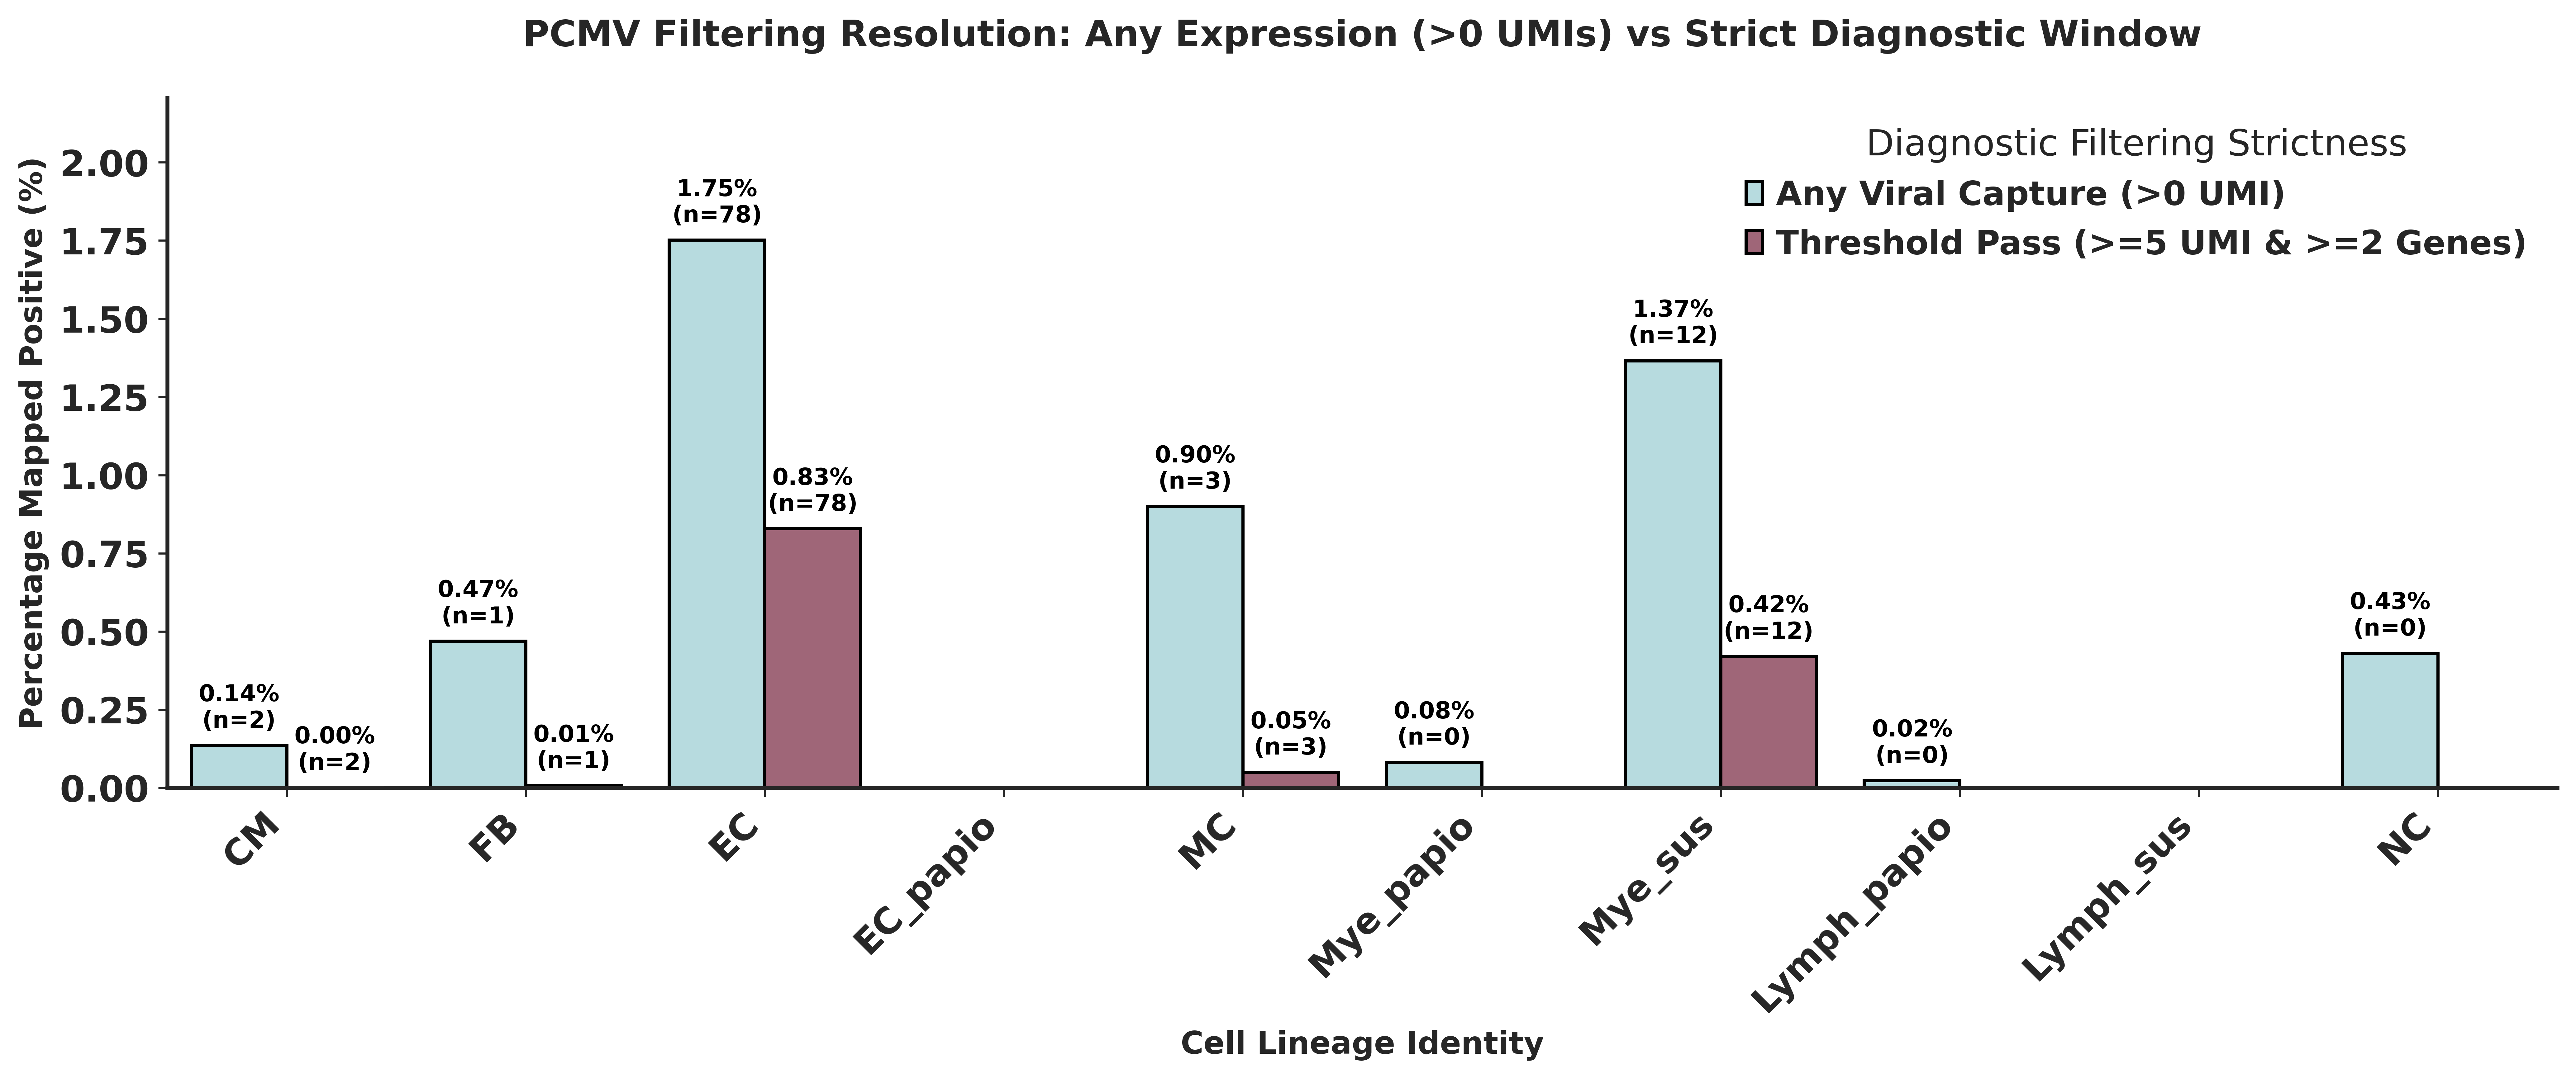


=== RAW COUNTS FILTERING LOG ===
  cell_type  Total_Cells  Any_Capture_Count  Passed_detection_threshold
         CM       182612                247                           2
         FB        15562                 73                           1
         EC         9422                165                          78
   EC_papio          166                  0                           0
         MC         6111                 55                           3
  Mye_papio        11076                  9                           0
    Mye_sus         2856                 39                          12
Lymph_papio         4340                  1                           0
  Lymph_sus          125                  0                           0
         NC          930                  4                           0


In [15]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib
import matplotlib.colors
import matplotlib.pyplot as plt
import seaborn as sns

adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/global_object_assembly/objects/global_PCMV_score_updated_celltype_cellstate_annotated_preclinical_object_v2.h5ad')

lineage_totals = adata.obs.groupby('cell_type', observed=False).size()

# Condition A: Any viral transcript capture (> 0 UMIs)
adata.obs['any_pcmv_capture'] = (adata.obs['n_counts_pCMV'] > 0).astype(int)
any_counts = adata.obs.groupby('cell_type', observed=False)['any_pcmv_capture'].sum()
any_pct = (any_counts / lineage_totals) * 100

# Condition B: High-confidence stringent window alignment (Passes Threshold)
adata.obs['strict_threshold_pass'] = adata.obs['PCMV_detection_threshold'].astype(int)
strict_counts = adata.obs.groupby('cell_type', observed=False)['strict_threshold_pass'].sum()
strict_pct = (strict_counts / lineage_totals) * 100

# Build Tidy Dataframe Matrix
plot_data = pd.DataFrame({
    'Total_Cells': lineage_totals,
    'Any_Capture_Count': any_counts,
    'Any_Capture_Pct': any_pct,
    'Passed_detection_threshold': strict_counts,
    'Strict_Pass_Pct': strict_pct
}).reset_index()

# Reshape into a side-by-side long format for plotting
melted_pct = pd.melt(
    plot_data, 
    id_vars=['cell_type', 'Any_Capture_Count', 'Passed_detection_threshold'], 
    value_vars=['Any_Capture_Pct', 'Strict_Pass_Pct'],
    var_name='Filtering_Status', 
    value_name='Percentage'
)

melted_pct = melted_pct.sort_values('cell_type')

# fig size
plt.figure(figsize=(14, 6))
sns.set_style("ticks")

ax = sns.barplot(
    data=melted_pct,
    x='cell_type',
    y='Percentage',
    hue='Filtering_Status',
    palette=['#B0E0E6', '#A85D75'],  # Custom Powder Blue vs Muted Distinct Pink
    edgecolor='black',
    linewidth=1.2
)

# Dynamic count flag overlay loops 
for p in ax.patches:
    height = p.get_height()
    if np.isnan(height) or height == 0:
        continue
        
    x_pos = p.get_x() + p.get_width() / 2.0
    cell_type_idx = int(np.round(p.get_x()))
    
    if p.get_facecolor()[:3] == matplotlib.colors.to_rgb('#B0E0E6'):
        raw_count = plot_data.iloc[cell_type_idx]['Any_Capture_Count']
    else:
        raw_count = plot_data.iloc[cell_type_idx]['Passed_detection_threshold']
        
    ax.annotate(
        f"{height:.2f}%\n(n={int(raw_count)})",
        (x_pos, height),
        ha='center', va='bottom',
        xytext=(0, 5), textcoords='offset points',
        fontsize=9, fontweight='bold', color='black'
    )

# visualization params
plt.title('PCMV Filtering Resolution: Any Expression (>0 UMIs) vs Strict Diagnostic Window', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Cell Lineage Identity', fontsize=12, fontweight='bold')
plt.ylabel('Percentage Mapped Positive (%)', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontweight='bold')
plt.yticks(fontweight='bold')

ax.set_ylim(0, ax.get_ylim()[1] * 1.2)

handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles=handles, 
    labels=['Any Viral Capture (>0 UMI)', 'Threshold Pass (>=5 UMI & >=2 Genes)'],
    title='Diagnostic Filtering Strictness', 
    frameon=False, 
    prop={'weight': 'bold'}  # Clean fix to prevent TypeError crashes
)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)

plt.tight_layout()
plt.show()

print("\n=== RAW COUNTS FILTERING LOG ===")
print(plot_data[['cell_type', 'Total_Cells', 'Any_Capture_Count', 'Passed_detection_threshold']].to_string(index=False))

# Violin plots of pcmv & proliferative genes

In [16]:

import os
import re
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
sc.settings.set_figure_params(dpi=300, dpi_save=300)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
matplotlib.rcParams["font.family"] = "sans-serif"
matplotlib.rcParams["font.sans-serif"] = ["Arial"]

adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/global_object_assembly/objects/global_X_UMAP_Added_PCMV_score_updated_celltype_cellstate_annotated_preclinical_object_RAW_v3.h5ad')

RESULTS_DIR = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/EC_states_violins'
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Applying log-normalization to full object prior to lineage subsetting...")
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
print("Log-normalization complete.")

print("Isolating Endothelial Cell ('EC') lineage population...")
adata_ec = adata[adata.obs['cell_type'] == 'EC'].copy()
print(f"Isolated {adata_ec.n_obs} endothelial single-cells.")

if adata_ec.n_obs == 0:
    raise ValueError("Fatal Error: No cells found matching cell_type == 'EC'. Check index annotation strings.")

# Target pcmv genes
target_genes = [
    'Sus_scrofa___DIAPH3', 'Sus_scrofa___NAV2', 'Sus_scrofa___TOP2A', 'Sus_scrofa___TPX2', 'Sus_scrofa___CENPF','Sus_scrofa___DLGAP5', 'Sus_scrofa___KIF11', 'Sus_scrofa___KIF18A', 'Sus_scrofa___POLE',
    'Sus_scrofa___LMNB1', 'Sus_scrofa___ANLN', 'Sus_scrofa___RACGAP1', 'Sus_scrofa___NDC80', 'Sus_scrofa___KIF4A', 'Sus_scrofa___UHRF1',
    'pCMV_____gp20', 'pCMV_____gp21', 'pCMV_____gp22', 'pCMV_____gp23', 'pCMV_____gp24', 'pCMV_____gp25','pCMV_____gp26', 'pCMV_____gp27'
]

missing_genes = [g for g in target_genes if g not in adata_ec.var_names]
if missing_genes:
    print(f"WARNING: Feature slots {missing_genes} not indexing inside object matrix.")
    for query in missing_genes:
        matches = [g for g in adata_ec.var_names if re.search(query.split('___')[-1], g, re.IGNORECASE)]
        print(f" -> Query '{query}' close alternative matches: {matches}")

active_genes = [g for g in target_genes if g in adata_ec.var_names]

agg_records = []

for gene in active_genes:
    print(f"\nProcessing expression layout for target feature: {gene}...")

    # Extract already-normalised expression vector
    expr_vals = adata_ec[:, gene].X
    if not isinstance(expr_vals, np.ndarray):
        expr_vals = expr_vals.toarray()
    expr_vals = expr_vals.flatten()

    df_plot = pd.DataFrame({
        'cell_state': adata_ec.obs['cell_state'].values,
        'Expression': expr_vals
    })
    df_plot['cell_state'] = df_plot['cell_state'].astype(str)
    state_order = sorted(df_plot['cell_state'].unique())

    # Aggregate mean log-norm expression per cell_state
    agg_row = (
        df_plot
        .groupby('cell_state', sort=True)['Expression']
        .mean()
        .rename(gene)
    )
    agg_records.append(agg_row)

    plt.figure(figsize=(5, 3.5))
    sns.set_style("ticks")

    # Plot Layer A: Violin
    ax = sns.violinplot(
        data=df_plot,
        x='cell_state',
        y='Expression',
        order=state_order,
        color='#FF6B00',
        linewidth=1.5,
        cut=0,
        inner=None,
        scale='width',
        width=0.5
    )

    sns.stripplot(
        data=df_plot,
        x='cell_state',
        y='Expression',
        order=state_order,
        color='black',
        size=2,
        alpha=0.4,
        jitter=0.25,
        dodge=False,
        zorder=3
    )

    plt.title(f"EC states: {gene}", fontsize=10, fontweight='bold', pad=10)
    plt.xlabel("EC states", fontsize=9, fontweight='bold')
    plt.ylabel(f"{gene} expression", fontsize=9, fontweight='bold')

    plt.xticks(rotation=45, ha='right', fontweight='bold', fontsize=8)
    plt.yticks(fontweight='bold', fontsize=8)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(True)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    plt.tight_layout()

    pdf_name = f"violin_plot_EC_states_{gene}.pdf"
    pdf_out_path = os.path.join(RESULTS_DIR, pdf_name)
    plt.savefig(pdf_out_path, dpi=300, bbox_inches='tight', transparent=True)
    plt.close()
    print(f" ->  Figure exported: {pdf_out_path}")
# Save the table
agg_df = pd.DataFrame(agg_records).T          # rows = cell_states, cols = genes
agg_df.index.name = 'cell_state'
agg_csv_path = os.path.join(RESULTS_DIR, 'supplemental_source_mean_lognorm_per_state.csv')
agg_df.to_csv(agg_csv_path)
print(f"\n -> Aggregated source table exported: {agg_csv_path}")

print("\nAll target violins and aggregated supplemental matrix generated successfully.")

Applying log-normalization to full object prior to lineage subsetting...
Log-normalization complete.
Isolating Endothelial Cell ('EC') lineage population...
Isolated 9422 endothelial single-cells.

Processing expression layout for target feature: Sus_scrofa___DIAPH3...


/tmp/ipykernel_3132565/709162889.py:106: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  ax = sns.violinplot(


 -> Manuscript Vector Figure exported: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/EC_states_violins/violin_plot_EC_states_Sus_scrofa___DIAPH3.pdf

Processing expression layout for target feature: Sus_scrofa___NAV2...


/tmp/ipykernel_3132565/709162889.py:106: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  ax = sns.violinplot(


 -> Manuscript Vector Figure exported: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/EC_states_violins/violin_plot_EC_states_Sus_scrofa___NAV2.pdf

Processing expression layout for target feature: Sus_scrofa___TOP2A...


/tmp/ipykernel_3132565/709162889.py:106: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  ax = sns.violinplot(


... (37 outputs left out)

/tmp/ipykernel_3132565/709162889.py:106: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  ax = sns.violinplot(


 -> Manuscript Vector Figure exported: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/EC_states_violins/violin_plot_EC_states_pCMV_____gp26.pdf

Processing expression layout for target feature: pCMV_____gp27...


/tmp/ipykernel_3132565/709162889.py:106: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  ax = sns.violinplot(


 -> Manuscript Vector Figure exported: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/EC_states_violins/violin_plot_EC_states_pCMV_____gp27.pdf

 -> Aggregated source table exported: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/EC_states_violins/supplemental_source_mean_lognorm_per_state.csv

All target violins and aggregated supplemental matrix generated successfully.


# Violin plots of pcmv & proliferative genes - colors to cell states

In [1]:
"""
=============================================================================
LINEAGE SUB-STATE ANALYSIS — snRNA-seq | Xenotransplant Cohort
ANALYSIS: Endothelial Cell (EC) Sub-state Expression Violins & Source Matrix
=============================================================================
"""

import os
import re
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# --- Adobe Illustrator Vector Graphics Compatibility ---
sc.settings.set_figure_params(dpi=300, dpi_save=300)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
matplotlib.rcParams["font.family"] = "sans-serif"
matplotlib.rcParams["font.sans-serif"] = ["Arial"]

adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/global_object_assembly/objects/global_X_UMAP_Added_PCMV_score_updated_celltype_cellstate_annotated_preclinical_object_RAW_v3.h5ad')

# --- Paths ---
RESULTS_DIR = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/EC_states_violins'
os.makedirs(RESULTS_DIR, exist_ok=True)

# =============================================================================
# LOG-NORMALIZATION ON FULL OBJECT — before any subsetting
# =============================================================================
print("Applying log-normalization to full object prior to lineage subsetting...")
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
print("Log-normalization complete.")

# =============================================================================
# LINEAGE EXTRACTION
# =============================================================================
print("Isolating Endothelial Cell ('EC') lineage population...")
adata_ec = adata[adata.obs['cell_type'] == 'EC'].copy()
print(f"Isolated {adata_ec.n_obs} endothelial single-cells.")

if adata_ec.n_obs == 0:
    raise ValueError("Fatal Error: No cells found matching cell_type == 'EC'. Check index annotation strings.")

# --- DYNAMIC COLOR EXTRACTION ---
# Map the explicit cell state categories to their corresponding hex codes from .uns
if 'cell_state_colors' in adata_ec.uns:
    state_categories = adata_ec.obs['cell_state'].cat.categories
    state_colors = adata_ec.uns['cell_state_colors']
    custom_palette = dict(zip(state_categories, state_colors))
    print("Successfully mapped 'cell_state_colors' to explicit categories.")
else:
    print("WARNING: 'cell_state_colors' not found in object .uns layer.")
    custom_palette = None

# =============================================================================
# TARGET FEATURE ASSIGNMENTS
# =============================================================================
target_genes = [
    'Sus_scrofa___DIAPH3', 'Sus_scrofa___NAV2', 'Sus_scrofa___TOP2A', 'Sus_scrofa___TPX2', 'Sus_scrofa___CENPF','Sus_scrofa___DLGAP5', 'Sus_scrofa___KIF11', 'Sus_scrofa___KIF18A', 'Sus_scrofa___POLE',
    'Sus_scrofa___LMNB1', 'Sus_scrofa___ANLN', 'Sus_scrofa___RACGAP1', 'Sus_scrofa___NDC80', 'Sus_scrofa___KIF4A', 'Sus_scrofa___UHRF1',
    'pCMV_____gp20', 'pCMV_____gp21', 'pCMV_____gp22', 'pCMV_____gp23', 'pCMV_____gp24', 'pCMV_____gp25','pCMV_____gp26', 'pCMV_____gp27'
]

missing_genes = [g for g in target_genes if g not in adata_ec.var_names]
if missing_genes:
    print(f"WARNING: Feature slots {missing_genes} not indexing inside object matrix.")
    for query in missing_genes:
        matches = [g for g in adata_ec.var_names if re.search(query.split('___')[-1], g, re.IGNORECASE)]
        print(f" -> Query '{query}' close alternative matches: {matches}")

active_genes = [g for g in target_genes if g in adata_ec.var_names]

# =============================================================================
# AGGREGATED SOURCE TABLE — one mean log-norm expression value per gene per state
# =============================================================================
agg_records = []

# =============================================================================
# VIOLIN PIPELINE LOOP
# =============================================================================
for gene in active_genes:
    print(f"\nProcessing expression layout for target feature: {gene}...")

    # Extract already-normalised expression vector
    expr_vals = adata_ec[:, gene].X
    if not isinstance(expr_vals, np.ndarray):
        expr_vals = expr_vals.toarray()
    expr_vals = expr_vals.flatten()

    df_plot = pd.DataFrame({
        'cell_state': adata_ec.obs['cell_state'].values,
        'Expression': expr_vals
    })
    df_plot['cell_state'] = df_plot['cell_state'].astype(str)
    state_order = sorted(df_plot['cell_state'].unique())

    # Aggregate mean log-norm expression per cell_state
    agg_row = (
        df_plot
        .groupby('cell_state', sort=True)['Expression']
        .mean()
        .rename(gene)
    )
    agg_records.append(agg_row)

    # -------------------------------------------------------------------------
    # Canvas Construction
    # -------------------------------------------------------------------------
    plt.figure(figsize=(4.5, 2.5))
    sns.set_style("ticks")

    # Plot Layer A: Violin with Dynamic Object Colors
    ax = sns.violinplot(
        data=df_plot,
        x='cell_state',
        y='Expression',
        order=state_order,
        hue='cell_state',          # Explicitly set hue to map palette safely in modern Seaborn
        palette=custom_palette,    # Maps to the dynamic dictionary generated upstream
        linewidth=1.5,
        cut=0,
        inner=None,
        scale='width',
        width=0.5,
        dodge=False,
        legend=False               # Suppress redundant legend
    )

    # Plot Layer B: Jittered single-cell points
    sns.stripplot(
        data=df_plot,
        x='cell_state',
        y='Expression',
        order=state_order,
        color='black',
        size=1,                  # Reduced size footprint for cleaner visual rendering
        alpha=0.4,
        jitter=0.25,
        dodge=False,
        zorder=3
    )

    plt.title(f"EC states: {gene}", fontsize=10, fontweight='bold', pad=10)
    plt.xlabel("EC states", fontsize=9, fontweight='bold')
    plt.ylabel(f"{gene} expression", fontsize=9, fontweight='bold')

    plt.xticks(rotation=45, ha='right', fontweight='bold', fontsize=8)
    plt.yticks(fontweight='bold', fontsize=8)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(True)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    plt.tight_layout()

    pdf_name = f"violin_plot_EC_states_{gene}.pdf"
    pdf_out_path = os.path.join(RESULTS_DIR, pdf_name)
    plt.savefig(pdf_out_path, dpi=300, bbox_inches='tight', transparent=True)
    plt.close()
    print(f" -> Figure exported: {pdf_out_path}")

# =============================================================================
# SAVE SINGLE AGGREGATED SOURCE TABLE (all genes × all states)
# =============================================================================
agg_df = pd.DataFrame(agg_records).T          # rows = cell_states, cols = genes
agg_df.index.name = 'cell_state'
agg_csv_path = os.path.join(RESULTS_DIR, 'supplemental_source_mean_lognorm_per_state.csv')
agg_df.to_csv(agg_csv_path)
print(f"\n -> Aggregated source table exported: {agg_csv_path}")

print("\nAll target violins and aggregated matrix generated.")

Applying log-normalization to full object prior to lineage subsetting...
Log-normalization complete.
Isolating Endothelial Cell ('EC') lineage population...
Isolated 9422 endothelial single-cells.
Successfully mapped 'cell_state_colors' to explicit categories.

Processing expression layout for target feature: Sus_scrofa___DIAPH3...


/tmp/ipykernel_3321344/4101997731.py:117: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  ax = sns.violinplot(


 -> Figure exported: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/EC_states_violins/violin_plot_EC_states_Sus_scrofa___DIAPH3.pdf

Processing expression layout for target feature: Sus_scrofa___NAV2...


/tmp/ipykernel_3321344/4101997731.py:117: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  ax = sns.violinplot(


 -> Figure exported: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/EC_states_violins/violin_plot_EC_states_Sus_scrofa___NAV2.pdf

Processing expression layout for target feature: Sus_scrofa___TOP2A...


/tmp/ipykernel_3321344/4101997731.py:117: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  ax = sns.violinplot(


... (37 outputs left out)

/tmp/ipykernel_3321344/4101997731.py:117: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  ax = sns.violinplot(


 -> Figure exported: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/EC_states_violins/violin_plot_EC_states_pCMV_____gp26.pdf

Processing expression layout for target feature: pCMV_____gp27...


/tmp/ipykernel_3321344/4101997731.py:117: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  ax = sns.violinplot(


 -> Figure exported: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/EC_states_violins/violin_plot_EC_states_pCMV_____gp27.pdf

 -> Aggregated source table exported: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/EC_states_violins/supplemental_source_mean_lognorm_per_state.csv

All target violins and aggregated matrix generated.


# UMAP of pCMV score

In [18]:
import os
import scanpy as sc
import matplotlib
import matplotlib.pyplot as plt
sc.settings.set_figure_params(dpi=300, dpi_save=300)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
matplotlib.rcParams["font.family"] = "sans-serif"
matplotlib.rcParams["font.sans-serif"] = ["Arial"]

# --- Paths ---
INPUT_PATH = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/global_object_assembly/objects/global_X_UMAP_Added_PCMV_score_updated_celltype_cellstate_annotated_preclinical_object_RAW_v3.h5ad'

RESULTS_DIR = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/pcmv_feature_plots'
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Loading preclinical AnnData object v2...")
adata = sc.read_h5ad(INPUT_PATH)

print("Generating UMAP projection for pCMV_score...")

fig, ax = plt.subplots(figsize=(5.5, 4.5))

# Generate the expression feature plot layout
sc.pl.umap(
    adata,
    color="pCMV_score",
    cmap="Oranges",        
    size=12,           
    frameon=True,      
    sort_order=True, 
    ax=ax,
    show=False
)


ax.set_title("pCMV Module Score", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("UMAP_1", fontsize=12, fontweight="bold")
ax.set_ylabel("UMAP_2", fontsize=12, fontweight="bold")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(True)
ax.spines["bottom"].set_visible(True)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)
ax.spines["left"].set_color("black")
ax.spines["bottom"].set_color("black"

ax.set_xticks([])
ax.set_yticks([])

plt.tight_layout()
out_pdf_path = os.path.join(RESULTS_DIR, "umap_pCMV_score_preclinical.pdf")
plt.savefig(out_pdf_path, dpi=300, bbox_inches='tight', transparent=True)
plt.close()

print(f"\nDone! UMAP figure saved successfully as crisp vector PDF at:\n -> {out_pdf_path}")

Loading preclinical AnnData object v2...


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

Generating UMAP projection for pCMV_score...


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because


Done! UMAP figure saved successfully as crisp vector PDF at:
 -> /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/pcmv_analysis/results/pcmv_feature_plots/umap_pCMV_score_preclinical.pdf
